**Main imports**

In [1]:
# import sys  # (uncomment for environemnt setup)
# !{sys.executable} -m pip install torch torchvision matplotlib lpips

import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from IPython import display as disp

# Additional imports
import random # for the randomseed (for ablation testing & report)
from torch.nn.utils import spectral_norm  # one of my early stabilisation steps is spectral normalisation
import time # just like in discriminator, I want to see how long model takes to run (particularly as this takes a lot longer)
import copy # for ema reporting

# + imports for fid generation
#%%capture
!pip install clean-fid
import os
from cleanfid import fid
from torchvision.utils import save_image
import shutil

# and then for the lpips evalulation for similarity between generated & the imported ciafr set
import lpips

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

In [2]:
'''
Note to examiner: Something seems to have broken in my determinsim at some point and the images being produced are a bit 
different with each run. However, this exact model/code is what produced the images in my report.
Also with each run, the FID is VERY similar (i.e. +/- 0.05).

'''
# this function was created for ablation testing, so I can incrementally test different additions to the model and measure their impact
def set_seed(seed=16): 
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(210)

**Import dataset**

In [3]:
# helper function to make getting another batch of data easier
def cycle(iterable):
    while True:
        for x in iterable:
            yield x

class_names = ['apple','aquarium_fish','baby','bear','beaver','bed','bee','beetle','bicycle','bottle','bowl','boy','bridge','bus','butterfly','camel','can','castle','caterpillar','cattle','chair','chimpanzee','clock','cloud','cockroach','couch','crab','crocodile','cup','dinosaur','dolphin','elephant','flatfish','forest','fox','girl','hamster','house','kangaroo','computer_keyboard','lamp','lawn_mower','leopard','lion','lizard','lobster','man','maple_tree','motorcycle','mountain','mouse','mushroom','oak_tree','orange','orchid','otter','palm_tree','pear','pickup_truck','pine_tree','plain','plate','poppy','porcupine','possum','rabbit','raccoon','ray','road','rocket','rose','sea','seal','shark','shrew','skunk','skyscraper','snail','snake','spider','squirrel','streetcar','sunflower','sweet_pepper','table','tank','telephone','television','tiger','tractor','train','trout','tulip','turtle','wardrobe','whale','willow_tree','wolf','woman','worm',]

train_loader = torch.utils.data.DataLoader(
    torchvision.datasets.CIFAR100('data', train=True, download=True, transform=torchvision.transforms.Compose([
        #torchvision.transforms.RandomHorizontalFlip(), # from the literature it seemed that this was really the only valid augmentation
        torchvision.transforms.ToTensor()
    ])),
    batch_size=64, drop_last=True)

test_loader = torch.utils.data.DataLoader(
    torchvision.datasets.CIFAR100('data', train=False, download=True, transform=torchvision.transforms.Compose([
        torchvision.transforms.ToTensor()
    ])),
    batch_size=64, drop_last=True)

train_iterator = iter(cycle(train_loader))
test_iterator = iter(cycle(test_loader))

print(f'> Size of training dataset {len(train_loader.dataset)}')
print(f'> Size of test dataset {len(test_loader.dataset)}')

> Size of training dataset 50000
> Size of test dataset 10000


**View some of the test dataset**

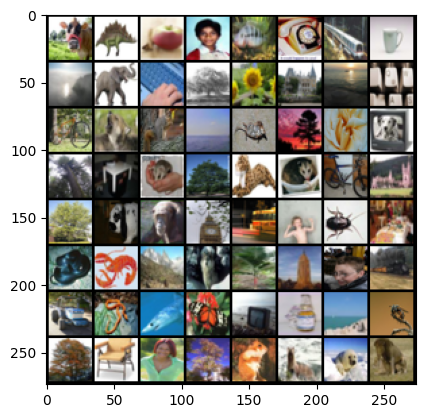

In [4]:
# let's view some of the training data
plt.rcParams['figure.dpi'] = 100
x,t = next(train_iterator)
x,t = x.to(device), t.to(device)
plt.imshow(torchvision.utils.make_grid(x).cpu().numpy().transpose(1, 2, 0), cmap=plt.cm.binary)
plt.show()

In [5]:
# i've set this up to counter the massive epoch runtimes
is_this_an_experimentation_run =False # this is the on/off switch for that
if is_this_an_experimentation_run:  # this is my 'run fast, check validity' mode, won't be used in final reporting as it limits performance
    print("Current Mode: Experimentation Run (limited compute & params for speed)")
    params = {
        'batch_size': train_loader.batch_size,
        'n_channels': 3,
        'n_latent': 40, # smaller latent gives a bit quicker iteration runtime
        'g_feature_maps': 40, # reduced width is significant on runtime too
        'd_feature_maps': 32,
    }
        
    hyperparams = {
        'num_training_steps': 10000, # these short runs work good-enough for benchmarking performance
        'disc_lr': 0.0002,
        'gen_lr': 0.00006,#0.0001,
        'betas': (0.0, 0.9),
        'discrim_update_ratio': 2,
        'ema': 0.999,
        'ema_warmup_steps': 1000, # i set this up so the ema effect isn't present right at the start, as it was too strong
        'late_generator_noise_mult': 1,  # this is an attempt to target noise that dominates after the structures already formed (negated w/ 1 for now)
        'embed_dim': 128,
        #         'num_steps_in_early_phase': 20000,  tried out this staged technique but it didn't seem to help
#         'lr_in_early_phase': 0.999, # and these lr tunings are artefacts of that same technique
#         'lr_in_late_phase': 0.9997,
        #'eval_interval_fid': 5000 # i did also try running fid test every 5k steps but this was a lot of extra complication for only a tiny drop in fid
        # that also accompanied a drop in realism too, so I got rid of it.
    }

else:  # and this is the full mode, computationally spenny but obviously produces better results by using full allowances
    print("Current mode: Full experimentation mode (full compute & params for performance)")
    params = {
        'batch_size': train_loader.batch_size,
        'n_channels': 3,
        'n_latent': 64,
        'g_feature_maps': 54,
        'd_feature_maps': 26,
    }
    
    hyperparams = {
        'num_training_steps': 50000, # max allowed by coursework
        'disc_lr': 0.0004,
        'gen_lr': 0.0001, # by default I found that a lower generator lr wrt discriminator is always better
        'betas': (0.0, 0.9), 
        'discrim_update_ratio': 2,
        'ema': 0.9995,
        'ema_warmup_steps': 1000,
        'late_generator_noise_mult': 1,
        'embed_dim': 128,
#         'num_steps_in_early_phase': 10000, # (described above, i'm leaving in for methodology transparancy)
#         'lr_in_early_phase': 0.999,
#         'lr_in_late_phase': 0.9997,
        #'eval_interval_fid': 5000
    }

Current mode: Full experimentation mode (full compute & params for performance)


To start, I use a simple DC-GAN as the baseline

In [6]:
'''
I'm using this in the generator to fill in missing structural img details as the model grows.
What it does at a high lvl is blow up the img space to double pixels to allow for more detail to be accounted for
This is pt1 of my "conditioning upgrade" following on from convolutions
'''
class UpsampleResidBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.upsample_img = nn.Upsample(scale_factor=2, mode="nearest") # core logic, stretching img grid using nearest nieghbor interpolating (doubling pixels so theres more room for data)

        # now for convolutions, deciding how to fill gaps w/ patterns that actually mean something
        self.conv1 = spectral_norm(nn.Conv2d(in_ch, out_ch, 3, padding=1))
        self.conv2 = spectral_norm(nn.Conv2d(out_ch, out_ch, 3, padding=1))

        # then comes batchnorms to keep pixel intensities in check
        # [dev note] I'm commenting these out as these actually introduced noise & suprissed high lvl detail
        # self.first_batchN = nn.BatchNorm2d(in_ch)
        # self.second_batchN = nn.BatchNorm2d(out_ch)

        # finally, skip conneciton
        self.skip_conv = nn.Conv2d(in_ch, out_ch, 1)

    def forward(self, x):
        # firstly normalise data & apply relu to prioritise most important features
        #hidden_rep = self.first_batchN(x) # [dev note]: one possible technique to deal w/ alpha-blur fuzziness could be to reduce normalisation here to allow sharper activiations/edges to form
        hidden_rep = x
        hidden_rep = F.relu(hidden_rep)
        
        # now expand out. 1st conv mapps out large features
        hidden_rep = self.upsample_img(hidden_rep)

        hidden_rep = self.conv1(hidden_rep)

        # then go again, going after finer details of enlarged img
        #hidden_rep = self.second_batchN(hidden_rep)
        hidden_rep = F.relu(hidden_rep)
        hidden_rep = self.conv2(hidden_rep)

        # stretch & adjust channels separatley
        skip_conn = self.upsample_img(x)
        skip_conn = self.skip_conv(skip_conn)

        # now return the learned difference between the low res input img and high res output one
        return hidden_rep + skip_conn

In [7]:
'''
Now this gets utilised in the discriminator to condense the img that's been worked on down to high-lvl features ready for judgement
Help to summarise & judge main shapes instead of every single detail
This is pt2 of that conditioning upgrade
'''
class DownsampleResidBlock(nn.Module):
    def __init__(self, in_ch, out_ch, first_block=False):
        super().__init__()
        self.first_block = first_block

        # [dev note]: i'm using spectral norm here to prevent it from becoming too strong too quick (which overpowers generator & causes mode collapse)
        self.conv1 = spectral_norm(nn.Conv2d(in_ch, out_ch, 3, padding=1))
        self.conv2 = spectral_norm(nn.Conv2d(out_ch, out_ch, 3, padding=1))
        self.skip_conv = spectral_norm(nn.Conv2d(in_ch, out_ch, 1))
        self.avg_pool = nn.AvgPool2d(2)

    def forward(self, x):
        # input path handling
        if self.first_block:
            # i don't apply relu just one the 1st layer
            hidden_rep = self.conv1(x) 
        else:
            # all other layers have relu then conv applied
            hidden_rep = F.relu(x)
            hidden_rep = self.conv1(hidden_rep)
            
        hidden_rep = F.relu(hidden_rep)
        hidden_rep = self.conv2(hidden_rep)
        hidden_rep = self.avg_pool(hidden_rep) # avg each 2x2 pixel grid into 1

        # now for a the skip connection to create the direct bypass-paths
        skip_conn = x
        skip_conn = self.avg_pool(skip_conn) # now pool & project
        skip_conn = self.skip_conv(skip_conn)

        return hidden_rep + skip_conn

In [8]:
'''
Now for my core logic classes, the real fundamentals of the literature that I'm basing my project off; 
generator & discriminators that use the upsample and downsample resid blocks from DCGAN. 
First up, this generator is taking the label & some random noise (as a vector) and translating to actual understandbly coherent imgs
'''
LATE_GEN_NOISE_MULT = hyperparams['late_generator_noise_mult'] # for controlling generator noise after structures formed
class Generator(nn.Module):
    def __init__(self, params):
        super().__init__()
        # first the latent dimensions are pulled from preset hyperparams (near the top of this notebook) & used to learn core dimensions of each img
        describing_dims = params['n_latent']
        base_ch = params['g_feature_maps']
        self.embed = nn.Embedding(100, describing_dims) # 100 because that's the num classes ciafr 100 has

        # method is to start with high-ish channels (3xbase) * scale down
        self.fc = nn.Linear(describing_dims * 2, (base_ch * 3) * 4 * 4) 

        # the 3 sets of upsampling to be applied sequentailly
        self.blk1 = UpsampleResidBlock(base_ch * 3, base_ch * 2)
        self.blk2 = UpsampleResidBlock(base_ch * 2, base_ch)
        self.blk3 = UpsampleResidBlock(base_ch, base_ch) # i'm keeping capacity high here

        # standard batchnorm here
        self.batch_n = nn.BatchNorm2d(base_ch)
        self.conv_out = spectral_norm(nn.Conv2d(base_ch, 3, 3, padding=1))

    def forward(self, describing_dims, ciafr_labels):
        y = self.embed(ciafr_labels)
        describing_dims = torch.cat([describing_dims, y], dim=1)
        hidden_rep = self.fc(describing_dims)
        hidden_rep = hidden_rep.view(describing_dims.size(0), -1, 4, 4)

        # all the 3 upsample blocks are now applied sequentailly
        hidden_rep = self.blk1(hidden_rep)
        hidden_rep = self.blk2(hidden_rep)
        hidden_rep = self.blk3(hidden_rep)
        hidden_rep = hidden_rep * LATE_GEN_NOISE_MULT # now counter for w/ late noise

        # ending w/ batch norm and reg relu (not relu6)
        hidden_rep = self.batch_n(hidden_rep)
        hidden_rep = F.relu(hidden_rep)
        hidden_rep = self.conv_out(hidden_rep)

        return torch.tanh(hidden_rep) # in line with literature, i'm using tanh in the last part of the generator

In [9]:
'''
Then, the discriminator acts as the "critic", looking at the outputs generated and alinging them to how close they are to the a ciafr class
'''
class Discriminator(nn.Module):
    def __init__(self, params):
        super().__init__()

        base_ch = params['d_feature_maps']
        num_classes = 100

        # firstly, downsampling channels
        self.block1 = DownsampleResidBlock(3, base_ch, first_block=True)
        self.block2 = DownsampleResidBlock(base_ch, base_ch * 2)
        self.block3 = DownsampleResidBlock(base_ch * 2, base_ch * 4)

        # now spectral norm to rescale params for each weight matrix
        self.linear = spectral_norm(nn.Linear(base_ch * 4, 1))

        # now i add compressed embedding into smaller space & then project upwards (saves params)
        embed_dim = hyperparams['embed_dim']
        feature_dim = base_ch * 4
        self.embed = spectral_norm(nn.Embedding(num_classes, embed_dim))
        self.embed_proj = spectral_norm(nn.Linear(embed_dim, feature_dim, bias=False)) # no bias as a standard for projection discriminators

    def forward(self, x, labels):
        hidden_rep = self.block1(x)
        hidden_rep = self.block2(hidden_rep)
        hidden_rep = self.block3(hidden_rep)
        hidden_rep = F.relu(hidden_rep)

        # now use global sum pooling to collapse 4x4 space to 1x1
        hidden_rep = torch.sum(hidden_rep, dim=[2, 3])

        # This is the 'real/fake' score
        prediction = self.linear(hidden_rep)

        # then compressed class embeddings are projecting into feature space
        class_embed = self.embed(labels) # i.e. learned vector representation of target class's label
        class_embed = self.embed_proj(class_embed)

        # Finally, projection term (dot product alignment between img feature & class embedding)
        direc_in_feature_space = torch.sum(hidden_rep * class_embed, dim=1, keepdim=True)

        return prediction + direc_in_feature_space

In [10]:
# now for the DCGAN class
# here the generator and discriminator are combined into the baseline model, adhering to dcgan archiecture and allowing me to calculate params to abide by coursework constraints
class DCGAN_baseline(nn.Module):
    def __init__(self, params):
        super().__init__()
        self.generator = Generator(params)
        self.discriminator = Discriminator(params)

    def sample(self, latent_v, ciafr_labels=None): # this takes in the labels to train w/ conditioning (i.e. i'm now training it to learn how close an image is to a ciafr label)
        was_training = self.generator.training  # track current mode for evalulating

        self.generator.eval()  # i use batchnorm in eval mode for sampling
        with torch.no_grad():
            if ciafr_labels is None:
                # if there aren't any ciafr labels provided, just sample them
                ciafr_labels = torch.randint(0, 100, (latent_v.size(0),), device=latent_v.device) 
 
            samp = self.generator(latent_v, ciafr_labels)

        if was_training:
            self.generator.train()  # go back to original mode

        samp = (samp + 1)/2.0  # here i'm rescaling (from [-1,1] to [0,1])
        return samp

In [11]:
# now a helper to run ema sampling
def sample_with_ema(shadow_ema, latent_v, ciafr_labels=None):
    shadow_ema.eval()
    with torch.no_grad():
        if ciafr_labels is None:
            # again, if there aren't any ciafr labels provided sample them
            ciafr_labels = torch.randint(0, 100, (latent_v.size(0),), device=latent_v.device)
        samp = shadow_ema(latent_v, ciafr_labels)
    return (samp + 1)/2.0

In [12]:
# now for the actual model initialisation
N = DCGAN_baseline(params).to(device)
ema_decay = hyperparams['ema']

# 1st I need to create a copy of generator as it stands right now
shadow_ema = copy.deepcopy(N.generator)
shadow_ema.eval()

for param in shadow_ema.parameters():
    param.requires_grad = False

# the total sum of params across generator & discriminator for coursework param reporting
n_params = sum(p.numel() for p in N.parameters() if p.requires_grad)

print(f"Total params: {n_params}")
if (n_params > 1000000):
    print("[WARNING]: OVER PARAM BUDGET")

# now the optimisers get defined for both generator & descriminator
discrim_optimiser = torch.optim.Adam( # Adam optimser seemed to be the best choice overall, so I didn't change unlike in pt1
    N.discriminator.parameters(),
    lr=hyperparams['disc_lr'], # I explicitly set discrim learning rate here
    betas=hyperparams['betas'],  # + feed in the betas
)
gen_optimiser = torch.optim.Adam( 
    N.generator.parameters(),
    lr=hyperparams['gen_lr'], # & generator learning rate set here
    betas=hyperparams['betas'],
)

Total params: 985796


In [13]:
# now I add in stabilising w/ hinge loss

# 1st in discriminator: this is for inforcing separation between fake & real samples
def d_hinge_loss(real_logits, fake_logits):
    loss_real = torch.mean(F.relu(1.0 - real_logits)) # real logits have to surpass this threshold
    loss_fake = torch.mean(F.relu(1.0 + fake_logits))# & fake ones this one
    return loss_real + loss_fake

# then in generator: this is helping maximise discriminators scoring
def g_hinge_loss(fake_logits):
    return -torch.mean(fake_logits) # fake logits better, so generator keeps pushing fake samples to look more real from discrim's pov

**Main training loop**

In [14]:
# I've added this dynamic num of training steps because by the time I got to convolutional upgrade,
# runtime started taking +1hr, which is too much for incremental upgrades
NUM_TRAIN_STEPS = hyperparams['num_training_steps']
# NOTE: 50,000 steps is the default number of training steps, which is what is used in my final submission.
DISCRIM_UPDATE_RATIO = hyperparams['discrim_update_ratio']  # controls how many updates discriminator gets wrt generator (inspired by TTUR)
LOG_INTERVAL = 1000  # printing results every 1k steps
EMA_WARMUP_STEPS = hyperparams['ema_warmup_steps']  # this is just the number of steps before ema kicks-off its smoothing

steps = 0  # counts optimisation steps per coursework definition (which I explain below)
start_time = time.time()

# fixed noise for final visualisation
fixed_z = torch.randn(params['batch_size'], params['n_latent'], device=device)

N.generator.train()
N.discriminator.train()

while steps < NUM_TRAIN_STEPS:
    d_loss_arr = []
    g_loss_arr = []

    for _ in range(LOG_INTERVAL):
        if steps >= NUM_TRAIN_STEPS:
            break

        # now the discriminator updates twice per generator update
        for _ in range(DISCRIM_UPDATE_RATIO):

            x_real, ciafr_labels = next(train_iterator)
            x_real = x_real.to(device)
            ciafr_labels = ciafr_labels.to(device)
            real_images = 2.0 * x_real - 1.0

            #z = torch.randn(params['batch_size'], params['n_latent'], device=device).clamp(-2, 2)  # applying latent clipping to remove extreme noise vectors to try to get rid of the blob shapes
            z = torch.randn(params['batch_size'], params['n_latent'], device=device)  # I removed .clamp(-2, 2)
            
            fake_images = N.generator(z, ciafr_labels).detach()

            real_logits = N.discriminator(real_images, ciafr_labels)
            fake_logits = N.discriminator(fake_images, ciafr_labels)

            d_loss = d_hinge_loss(real_logits, fake_logits)

            discrim_optimiser.zero_grad()
            d_loss.backward()
            discrim_optimiser.step()

        # the one update for the generator
        #z = torch.randn(params['batch_size'], params['n_latent'], device=device).clamp(-2, 2)  # latent clipping here too
        z = torch.randn(params['batch_size'], params['n_latent'], device=device)  # removed .clamp(-2, 2)
        
        fake_images = N.generator(z, ciafr_labels)

        gen_optimiser.zero_grad()
        fake_logits = N.discriminator(fake_images, ciafr_labels)
        g_loss = g_hinge_loss(fake_logits)

        g_loss.backward()
        gen_optimiser.step()

        # now ema update (but w/ warmup)
        with torch.no_grad():
            if steps < EMA_WARMUP_STEPS:
                # During warm-up I keep EMA identical to live generator
                for ema_params, param in zip(shadow_ema.parameters(), N.generator.parameters()):
                    ema_params.data.copy_(param.data)
                for buffer_ema, buf in zip(shadow_ema.buffers(), N.generator.buffers()):
                    buffer_ema.copy_(buf)
            else:
                # After warm-up I apply exponential moving average
                for ema_params, param in zip(shadow_ema.parameters(), N.generator.parameters()):
                    ema_params.data.mul_(ema_decay).add_(param.data, alpha=1.0 - ema_decay)
                for buffer_ema, buf in zip(shadow_ema.buffers(), N.generator.buffers()):
                    buffer_ema.copy_(buf)

        d_loss_arr.append(d_loss.item())
        g_loss_arr.append(g_loss.item())

        # Note: as clarified by email, one optimisation step is 1 discriminator + 1 generator update, so the other discriminator step is counted as a second optimisation step
        # therefore i'm doing 25k cycles of updating the discriminator twice and the generator once
        steps += DISCRIM_UPDATE_RATIO  # counting optimisation steps

    # now I log generator & discriminator loss results + time elapsed (out of interest)
    elapsed = time.time() - start_time
    hrs = int(elapsed // 3600)
    mins = int((elapsed % 3600) // 60)
    secs = int(elapsed % 60)

    print(
        f"steps {steps}, "
        f"D loss: {np.mean(d_loss_arr):.3f}, "
        f"G loss: {np.mean(g_loss_arr):.3f}, "
        f"elapsed: {hrs:02d}:{mins:02d}:{secs:02d}"
    )

steps 2000, D loss: 1.221, G loss: 0.358, elapsed: 00:01:25
steps 4000, D loss: 1.238, G loss: 0.318, elapsed: 00:02:48
steps 6000, D loss: 1.299, G loss: 0.253, elapsed: 00:04:37
steps 8000, D loss: 1.314, G loss: 0.263, elapsed: 00:06:38
steps 10000, D loss: 1.349, G loss: 0.310, elapsed: 00:08:39
steps 12000, D loss: 1.397, G loss: 0.315, elapsed: 00:10:36
steps 14000, D loss: 1.415, G loss: 0.285, elapsed: 00:12:37
steps 16000, D loss: 1.430, G loss: 0.387, elapsed: 00:14:24
steps 18000, D loss: 1.434, G loss: 0.319, elapsed: 00:15:45
steps 20000, D loss: 1.440, G loss: 0.339, elapsed: 00:17:06
steps 22000, D loss: 1.458, G loss: 0.331, elapsed: 00:18:30
steps 24000, D loss: 1.461, G loss: 0.291, elapsed: 00:19:52
steps 26000, D loss: 1.467, G loss: 0.330, elapsed: 00:21:15
steps 28000, D loss: 1.473, G loss: 0.355, elapsed: 00:22:37
steps 30000, D loss: 1.484, G loss: 0.343, elapsed: 00:23:57
steps 32000, D loss: 1.476, G loss: 0.346, elapsed: 00:25:18
steps 34000, D loss: 1.491, 

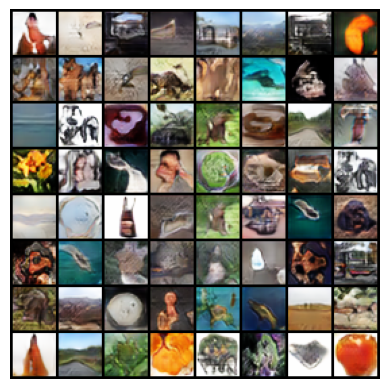

In [15]:
# now training is done; time to evaluate what the results were
N.generator.eval()

with torch.no_grad():
    z = torch.randn(params['batch_size'], params['n_latent'], device=device)
    z = z.clamp(-2, 2)
    samples_batch = sample_with_ema(shadow_ema, z).cpu() # here the ema sampling is done too

plt.rcParams['figure.dpi'] = 100
plt.grid(False)
plt.imshow(
    torchvision.utils.make_grid(samples_batch)
        .cpu()
        .numpy()
        .transpose(1, 2, 0),
    cmap=plt.cm.binary
)
#plt.title("Final generated samples") # (I've only commented out for the report)
plt.axis("off")
plt.show()

**Latent interpolations**

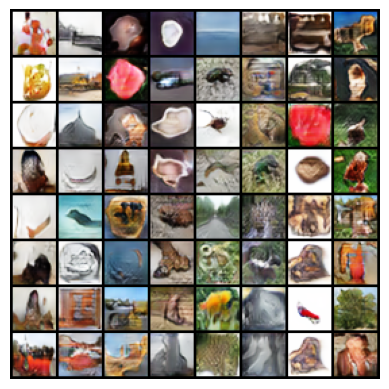

In [16]:
# now show some interpolations

# Latent interpolations - I stuck with linear with logic provided from coursework template
col_size = int(np.sqrt(params['batch_size']))

z0 = z[0:col_size].repeat(col_size,1) # z for top row
z1 = z[params['batch_size']-col_size:].repeat(col_size,1) # z for bottom row

t = torch.linspace(0,1,col_size).unsqueeze(1).repeat(1,col_size).view(params['batch_size'],1).to(device)

lerp_z = (1-t)*z0 + t*z1 # linearly interpolate between two points in the latent space
# now as noise shifts, class remains fixed
fixed_labels = torch.randint(0, 100, (params['batch_size'],), device=device) # labels are resused from top
#lerp_g = N.sample(lerp_z, fixed_labels)
lerp_g = sample_with_ema(shadow_ema, lerp_z, fixed_labels)

plt.rcParams['figure.dpi'] = 100
plt.grid(False)
plt.axis('off')
plt.imshow(torchvision.utils.make_grid(lerp_g).cpu().numpy().transpose(1, 2, 0), cmap=plt.cm.binary)
plt.show()

**FID scores**

Evaluate the FID from 10k of your model samples (do not sample more than this) and compare it against the 10k test images. Calculating FID is somewhat involved, so we use a library for it. It can take a few minutes to evaluate. Lower FID scores are better.

FULL CREDIT FOR THIS CELL: DL GENERATOR COURSEWORK TEMPLATE

In [17]:
# FULL CREDIT FOR THIS CELL: DL GENERATOR COURSEWORK TEMPLATE

# define directories
real_images_dir = 'real_images'
generated_images_dir = 'generated_images'
num_samples = 10000  # do not change

# create/clean the directories
def setup_directory(directory):
    if os.path.exists(directory):
        shutil.rmtree(directory)
    os.makedirs(directory)

setup_directory(real_images_dir)
setup_directory(generated_images_dir)

# here the mode is set to eval for fid
N.generator.eval()

# generate and save 10k model samples
set_seed(12345) # set for consistency
num_generated = 0
with torch.no_grad():
    while num_generated < num_samples:

        z = torch.randn(params['batch_size'], params['n_latent'], device=device)
        #samples_batch = N.sample(z).cpu()
        samples_batch = sample_with_ema(shadow_ema, z).cpu()

        for image in samples_batch:
            if num_generated >= num_samples:
                break
            
            save_image(
                image,
                os.path.join(generated_images_dir, f"gen_img_{num_generated}.png")
            )
            
            num_generated += 1

# save 10k images from the CIFAR-100 test dataset
num_saved_real = 0
while num_saved_real < num_samples:
    real_samples_batch, _ = next(test_iterator)
    for image in real_samples_batch:
        if num_saved_real >= num_samples:
            break
        
        save_image(
            image,
            os.path.join(real_images_dir, f"real_img_{num_saved_real}.png")
        )
        
        num_saved_real += 1

In [18]:
# FULL CREDIT FOR THIS CELL: DL GENERATOR COURSEWORK TEMPLATE
# compute FID
score = fid.compute_fid(real_images_dir, generated_images_dir, mode="clean")
print(f"FID score: {score}")

compute FID between two folders


/home2/xtzv61/dlcoursework/lib/python3.10/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Found 10000 images in the folder real_images


FID real_images : 100%|██████████| 313/313 [00:41<00:00,  7.51it/s]


Found 10000 images in the folder generated_images


FID generated_images : 100%|██████████| 313/313 [00:38<00:00,  8.10it/s]


FID score: 38.03945918098162


In [23]:
# I wanted all these to be repetable so I added this randomseed logic in
# I learnt the fundamentals for doing this from https://lightning.ai/docs/torchmetrics/stable/image/learned_perceptual_image_patch_similarity.html
SEED_FOR_REPEATABLE_LPIPS = 30
random.seed(SEED_FOR_REPEATABLE_LPIPS)
np.random.seed(SEED_FOR_REPEATABLE_LPIPS)
torch.manual_seed(SEED_FOR_REPEATABLE_LPIPS)
torch.cuda.manual_seed_all(SEED_FOR_REPEATABLE_LPIPS)
# so the same output that I showed in the report can be reproduced, I'm setting up all the determinsm logic here
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
COMPS_FROM_GENERATED_SET = 64 # I'm matching this up to the number of evalulated imgs above
COMPS_FROM_REAL_POOL = 10000 # and computation wasn't to expensive to use the whole pool of imported ciafr imgs

# lpips setup starts here now
loss_fn = lpips.LPIPS(net='alex').to(device).eval()

# I create this new iterator so it starts from beginning of dataset always
brand_new_iterator = iter(train_loader) 

set_of_comparison_imgs = []
curr_num = 0

print("setting up the collection of generated imgs to compare w/ real imgs...")
while curr_num < COMPS_FROM_REAL_POOL:
    batch, _ = next(brand_new_iterator)
    batch = batch.to(device)
    set_of_comparison_imgs.append(batch)
    curr_num += batch.size(0)
set_of_comparison_imgs = torch.cat(set_of_comparison_imgs, dim=0)[:COMPS_FROM_REAL_POOL] 

# now imgs get generated
z_sample = torch.randn(COMPS_FROM_GENERATED_SET, params['n_latent'], device=device)
labels_sample = torch.randint(0, 100, (COMPS_FROM_GENERATED_SET,), device=device)
with torch.no_grad():
    gen_imgs = sample_with_ema(shadow_ema, z_sample, labels_sample)

# then lpips metric is computed
lpips_comps_distances = []
print(f"a comparison of {COMPS_FROM_GENERATED_SET} generated imgs with {set_of_comparison_imgs.size(0)} real ones...")

for img_num in range(COMPS_FROM_GENERATED_SET):
    gen_img = gen_imgs[img_num].unsqueeze(0) # pulling out next img for comparison
    # i.e. I'm doing 1 generated img compared w/ entire ciafr 100 loaded imgs
    dist_between = ((gen_img - set_of_comparison_imgs) ** 2).sum(dim=(1, 2, 3))
    
    # top 20 pulled here for mean calculation
    candidates_place_indx = dist_between.topk(20, largest=False).indices # the indicies are 1st fetched...
    top_20_candidates = set_of_comparison_imgs[candidates_place_indx] # then they're actually pulled out using them
    gener_scaled = gen_img * 2 - 1 # the scale logic is next up
    candidate_scaled = top_20_candidates * 2 - 1
    
    # now i'm finding the mean on only top 20 (reduced compute, still seems perfectly valid from literature)
    with torch.no_grad(): # the 'perceptual' dist across all the filtered candidate set is what's being evalulated now
        lpips_scores = loss_fn(gener_scaled.repeat(top_20_candidates.size(0), 1, 1, 1),  candidate_scaled) 
    lpips_comps_distances.append(lpips_scores.min().item())

# now all that calculations done, its displayed below
mean_lpips_for_report = sum(lpips_comps_distances) / len(lpips_comps_distances)
print(f"the mean LPIPS distance (from top 20 candidates) to nearest real neighbour is...: {mean_lpips_for_report:.4f}")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: /home2/xtzv61/dlcoursework/lib/python3.10/site-packages/lpips/weights/v0.1/alex.pth
setting up the collection of generated imgs to compare w/ real imgs...
a comparison of 64 generated imgs with 10000 real ones...
the mean LPIPS distance (from top 20 candidates) to nearest real neighbour is...: 0.0985
